[All milestones](../START_HERE.ipynb) · [Main solution](../solution/reduced_qubit_hybrid_hourly.ipynb)

# Milestone 4 — hour-by-hour QAOA versus random sampling

The original simulator method and its 50 required trials (two samplers × five shot budgets × five seeds). Run top to bottom for fresh single-day examples and the saved benchmark table. Set `RERUN_BENCHMARK=True` to repeat the entire local sweep.

Costs from invalid schedules are not feasible solutions. The checker reports violations, and the benchmark reports valid-day rates separately from valid cost gaps. The [reduced-qubit solution](../solution/reduced_qubit_hybrid_hourly.ipynb) is a later extension.

In [1]:
# Resolve data and shared helpers when opening a notebook from its own folder.
from pathlib import Path
import os
import sys
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'src/check.py').is_file() and (p / 'data').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook inside the cloned project.')
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
os.chdir(PROJECT_ROOT)


In [2]:
# Use the qBraid-SDK (v0.12.2) kernel. This stops with a clear message if another one is picked.
import importlib.util
missing = [m for m in ("qbraid", "matplotlib") if importlib.util.find_spec(m) is None]
if missing:
    raise ImportError("Wrong kernel: this one has no " + " or ".join(missing) + ". Click the kernel name "
                      "at the top right of the notebook, pick qBraid-SDK (v0.12.2), then run this cell again.")

# Qiskit Aer is Qiskit's simulator. It runs right here in your Lab instance: instant, free and noise-free,
# with no remote job. Select an environment that already includes it.
try:
    import qiskit_aer  # noqa: F401
except ImportError:
    raise ImportError("Use a qBraid environment with qiskit-aer installed.")

import time

import numpy as np
import matplotlib.pyplot as plt
import scipy
from scipy.optimize import minimize
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator

from check import (load_plants, load_demand, solve_milp, check_schedule, check_hour,
                   hour_ok, hour_cost, locks)

plants = load_plants()              # data/plants.csv
demand, reserve = load_demand()     # data/demand.csv (MW for each of the 24 hours)
N = len(plants)                     # 5 plants
names = [p["plant_id"] for p in plants]
hours = np.arange(len(demand))
COLORS = {"milp": "#2a78d6", "qaoa": "#eb6834", "rule": "#1baf7a", "random": "#8a8984"}
print(f"{N} plants, {len(demand)} hours")

print("Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.")

5 plants, 24 hours
Setup OK: the qBraid kernel and Qiskit Aer are ready. You're good to go.


MILP solved in 0.050 s
Total cost: $327,924  (startups $32,930, no-load $20,178, energy $274,816)
MILP optimum: $327,924   gap: +0.00%
Valid: every hour meets demand and reserve; no min up/down rule is broken.


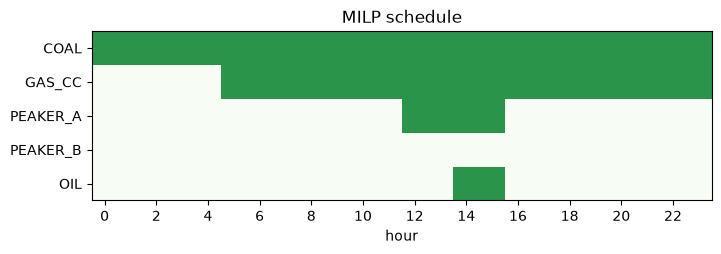

In [3]:
milp_cost, milp_schedule, milp_dispatch, secs = solve_milp(plants, demand, reserve)
print(f"MILP solved in {secs:.3f} s")
milp_result = check_schedule(plants, demand, reserve, milp_schedule, milp_cost=milp_cost)


def plot_schedule(schedule, title, ax=None):
    # Green = on. One row per plant, one column per hour.
    if ax is None:
        ax = plt.subplots(figsize=(8, 2.2))[1]
    ax.imshow(np.asarray(schedule).T, aspect="auto", cmap="Greens", vmin=0, vmax=1.4)
    ax.set_yticks(range(N), names)
    ax.set_xticks(range(0, len(demand), 2))
    ax.set_xlabel("hour")
    ax.set_title(title)
    return ax


plot_schedule(milp_schedule, "MILP schedule")
plt.show()

In [4]:
def plant_hour_costs(plants, was_on):
    c = np.zeros(len(plants))

    marginal_cheapest = min(
        p["marginal_cost_per_mwh"] for p in plants
    )

    for i, p in enumerate(plants):
        startup = p["startup_cost"] * (1 - was_on[i])
        no_load = p["no_load_cost_per_h"]
        extra_energy = p["pmin_mw"] * (
            p["marginal_cost_per_mwh"] - marginal_cheapest
        )

        c[i] = startup + no_load + extra_energy

    return c

In [5]:
BLOCK_MW = 50
N_SLACK = 3
N_QUBITS = N + N_SLACK


def build_qubo(plants, demand_mw, reserve_mw, was_on, penalty=None):
    c = plant_hour_costs(plants, was_on)
    A = 2 * c.max() if penalty is None else penalty

    # Plant capacity weights, followed by negative slack weights.
    b = np.array(
        [p["pmax_mw"] / BLOCK_MW for p in plants]
        + [-(2 ** k) for k in range(N_SLACK)]
    )

    # Required capacity in 50 MW blocks.
    r = np.ceil((demand_mw + reserve_mw) / BLOCK_MW)

    Q = np.zeros((N_QUBITS, N_QUBITS))
    offset = 0.0

    # Approximate operating costs.
    for i in range(len(plants)):
        Q[i, i] += c[i]

    # Capacity penalty: A * (sum(b[j] * y[j]) - r)**2.
    for j in range(N_QUBITS):
        Q[j, j] += A * (b[j] ** 2 - 2 * r * b[j])

        for k in range(j + 1, N_QUBITS):
            Q[j, k] += 2 * A * b[j] * b[k]

    offset += A * r ** 2

    return Q, offset

In [6]:
# Bit j of an integer index = qubit j. Row k of INDEX_BITS holds the 8 bits of index k.
# (Qiskit prints bitstrings with qubit 0 as the LAST character. Using integer indices
#  everywhere means you never have to reverse a string.)
INDEX_BITS = (np.arange(2 ** N_QUBITS)[:, None] >> np.arange(N_QUBITS)) & 1
PLANT_INDEX = INDEX_BITS[:, :N] @ (2 ** np.arange(N))   # on/off choice (0..31) inside each index


def all_energies(Q, offset):
    # QUBO energy of every bitstring in the configured state table.
    U = np.triu(Q)
    return np.einsum("bj,jk,bk->b", INDEX_BITS, U, INDEX_BITS) + offset


def brute_force_qubo(Q, offset):
    E = all_energies(Q, offset)
    k = int(np.argmin(E))
    return INDEX_BITS[k], E[k]


def label(choice):
    # Plant names for an on/off choice given as a 0..31 index or a list of 0/1.
    on = [(choice >> i) & 1 for i in range(N)] if np.isscalar(choice) else choice
    return "+".join(n for n, u in zip(names, on) if u) or "none"

In [7]:
def qubo_to_ising(Q):
    # y = (1 - z) / 2 turns the QUBO into  sum_j h_j Z_j + sum_jk J_jk Z_j Z_k + constant.
    h, J = np.zeros(len(Q)), {}
    for j in range(len(Q)):
        h[j] -= Q[j, j] / 2
        for k in range(j + 1, len(Q)):
            if Q[j, k] != 0:
                J[(j, k)] = Q[j, k] / 4
                h[j] -= Q[j, k] / 4
                h[k] -= Q[j, k] / 4
    return h, J


def qaoa_circuit(Q, p=1):
    # Parameterized QAOA circuit with p layers. Returns (circuit, parameters).
    h, J = qubo_to_ising(Q)
    scale = max(np.abs(h).max(), max(abs(v) for v in J.values()))   # keeps angles in a sane range
    gammas, betas = ParameterVector("gamma", p), ParameterVector("beta", p)
    qc = QuantumCircuit(len(Q))
    qc.h(range(len(Q)))
    for layer in range(p):
        for j, hj in enumerate(h):
            if hj != 0:
                qc.rz(2 * gammas[layer] * hj / scale, j)
        for (j, k), Jjk in J.items():
            qc.rzz(2 * gammas[layer] * Jjk / scale, j, k)
        qc.rx(2 * betas[layer], range(len(Q)))
    return qc, list(gammas) + list(betas)


def run_qaoa(Q, offset, p=1, start=None, maxiter=60):
    # Tune angles on the exact statevector; return angles and basis-state probabilities.
    E = all_energies(Q, offset)
    E = (E - E.min()) / (E.max() - E.min())
    qc, params = qaoa_circuit(Q, p)

    def probs_at(angles):
        return Statevector(qc.assign_parameters(dict(zip(params, angles)))).probabilities()

    def average_energy(angles):
        return probs_at(angles) @ E

    if start is None or len(start) != 2 * p:     # coarse grid for one (gamma, beta), used in every layer
        grid = [(g, b) for g in np.linspace(0.1, 3.0, 15) for b in np.linspace(0.1, 1.5, 8)]
        g, b = min(grid, key=lambda gb: average_energy([gb[0]] * p + [gb[1]] * p))
        start = [g] * p + [b] * p
    result = minimize(average_energy, start, method="COBYLA", options={"maxiter": maxiter, "rhobeg": 0.2})
    return result.x, probs_at(result.x)


def choice_probs(probs):
    # Plant on/off probabilities, marginalized over the slack qubits.
    return np.bincount(PLANT_INDEX, weights=probs, minlength=2 ** N)

## 5. The whole day, hour by hour (Milestone 4)

`schedule_day` goes through the 24 hours in order. For each hour it:

1. Asks `check.locks` which plants min up / min down times force on or off (classical).
2. Builds your QUBO, plus a penalty for breaking those locks.
3. Runs QAOA, starting from the previous hour's angles (warm start).
4. Draws `shots` samples, like a quantum computer would.
5. Keeps the cheapest sampled on/off choice that passes the classical check (`hour_ok`, exact `hour_cost`).
6. Carries that choice forward as "who was on" for the next hour.

If no sample passes, it keeps a choice that breaks a lock (or, failing that, the most common sample), and the checker lists the broken rule.

In [8]:
def add_locks(Q, offset, must_on, must_off, weight):
    # Penalty weight*(1 - x_i) for a plant that must stay on, weight*x_i for one that must stay off.
    Q = Q.copy()
    for i in must_on:
        Q[i, i] -= weight
        offset += weight
    for i in must_off:
        Q[i, i] += weight
    return Q, offset


def schedule_day(p=1, shots=200, sampler="qaoa", seed=7, penalty=None):
    rng = np.random.default_rng(seed)
    history, log, angles = [], [], None
    was_on = [int(x["on_at_start"]) for x in plants]
    for t in hours:
        must_on, must_off = locks(plants, history)
        Q, offset = build_qubo(plants, demand[t], reserve[t], was_on, penalty=penalty)
        Q, offset = add_locks(Q, offset, must_on, must_off, weight=2 * plant_hour_costs(plants, was_on).max())
        if sampler == "qaoa":
            angles, probs = run_qaoa(Q, offset, p=p, start=angles)
        else:                                   # random guessing, for comparison
            probs = np.full(2 ** N_QUBITS, 1 / 2 ** N_QUBITS)
        samples = rng.choice(2 ** N_QUBITS, size=shots, p=probs / probs.sum())
        seen = [list(INDEX_BITS[k][:N]) for k in np.unique(PLANT_INDEX[samples])]
        ok = [c for c in seen if hour_ok(plants, demand[t], reserve[t], c, must_on, must_off)]
        if not ok:                              # nothing fully valid: allow breaking a lock
            ok = [c for c in seen if hour_ok(plants, demand[t], reserve[t], c)]
        if ok:
            pick = min(ok, key=lambda c: hour_cost(plants, demand[t], c, was_on))
        else:                                   # still nothing: take the most common sample
            pick = list(INDEX_BITS[np.bincount(PLANT_INDEX[samples]).argmax()][:N])
        ref = check_hour(plants, demand[t], reserve[t], pick, was_on, must_on, must_off, verbose=False)
        best_k = None if ref["best_choice"] is None else int(np.dot(ref["best_choice"], 2 ** np.arange(N)))
        valid_share = np.mean([hour_ok(plants, demand[t], reserve[t], INDEX_BITS[k][:N], must_on, must_off)
                               for k in samples])
        log.append(dict(hour=t, pick=pick, matches_best=ref["matches_best"], valid_share=valid_share,
                        p_best=0.0 if best_k is None else choice_probs(probs)[best_k],
                        Q=Q, offset=offset, angles=angles))
        history.append(pick)
        was_on = pick
    return np.array(history), log

In [9]:
start = time.perf_counter()
qaoa_schedule, qaoa_log = schedule_day(p=1, shots=200)
print(f"QAOA for 24 hours: {time.perf_counter() - start:.1f} s\n")
qaoa_result = check_schedule(plants, demand, reserve, qaoa_schedule, milp_cost=milp_cost)

print(f"\n{'hour':>4}  {'choice':<28}{'best for this hour?':>20}{'P(best)':>9}{'valid samples':>15}")
for row in qaoa_log:
    print(f"{row['hour']:>4}  {label(row['pick']):<28}{'yes' if row['matches_best'] else 'no':>20}"
          f"{row['p_best']:>9.3f}{row['valid_share']:>14.0%}")

QAOA for 24 hours: 2.7 s

Total cost: $351,082  (startups $43,360, no-load $26,163, energy $281,559)
MILP optimum: $327,924   gap: +7.06%
Valid: every hour meets demand and reserve; no min up/down rule is broken.

hour  choice                       best for this hour?  P(best)  valid samples
   0  COAL                                         yes    0.049           70%
   1  COAL                                         yes    0.049           70%
   2  COAL                                         yes    0.049           70%
   3  COAL                                         yes    0.049           66%
   4  COAL                                         yes    0.049           66%
   5  COAL+OIL                                     yes    0.042           60%
   6  COAL+PEAKER_A+OIL                            yes    0.034           46%
   7  COAL+PEAKER_A+PEAKER_B+OIL                   yes    0.048           30%
   8  COAL+GAS_CC+PEAKER_A+PEAKER_B                 yes    0.070           15%
   9

## 6. Results vs the baseline

As an honesty check, the same loop also runs with random guesses instead of QAOA. Compare them: if random guessing does as well, what is making your schedule good? Look at every step of the loop, not just the sampler, before you answer.

**Required for milestone 4:** run QAOA and random guessing at 5, 10, 20, 50 and 200 shots, with at least 5 seeds each (`schedule_day(shots=..., sampler=..., seed=...)`). Make a table: how many days come out valid, and the cost gap of the valid ones. Explain it before you tune anything.

Then try:
- More layers (`p=2`), more optimizer steps, or a smaller penalty weight (`schedule_day(penalty=...)`; the default is 2 × the biggest plant cost).
- Why does the hour-by-hour schedule cost more than the MILP?

In [10]:
#Change this number to 5, 10, 20, 50, or 200
SHOTS = 200

#Change the seed to test different random runs 1-5
SEED = 5

random_schedule, random_log = schedule_day(
    shots=SHOTS,
    sampler="random",
    seed=SEED
)

print(f"Random sampling with {SHOTS} shots, seed={SEED}")

random_result = check_schedule(
    plants,
    demand,
    reserve,
    random_schedule,
    milp_cost=milp_cost
)



Random sampling with 200 shots, seed=5
Total cost: $353,363  (startups $43,360, no-load $26,857, energy $283,146)
MILP optimum: $327,924   gap: +7.76%
Valid: every hour meets demand and reserve; no min up/down rule is broken.


### Required experiment: QAOA versus random sampling

This runs 50 local ideal-simulator schedules: 2 samplers × 5 shot budgets × 5 sampling seeds (0–4), with p=1 and the default penalties. No cloud jobs are submitted. Each QAOA run includes fresh angle tuning. Runtime includes scheduling and validation; the full-day MILP baseline is computed separately. Seeds vary samples, not optimizer initialization.

Cost gaps include **valid schedules only**; a dash means no valid days. Valid samples is the average across all hours and seeds, each on its own evolving schedule history, so it is not a comparison of identical hourly inputs. Five seeds are an initial experiment, not strong statistical evidence. Raw runs and summary are saved as CSVs in results/.


In [11]:
# Saved 50-trial evidence is the default; opt in to repeat the local benchmark.
import csv
from pathlib import Path
from benchmark import run_benchmark, display_summary
RERUN_BENCHMARK = False
if RERUN_BENCHMARK:
    benchmark_runs, benchmark_summary = run_benchmark(
        schedule_day, check_schedule, plants, demand, reserve, milp_cost,
        shots_grid=(5, 10, 20, 50, 200), seeds=range(5))
else:
    with Path('results/benchmark_runs.csv').open() as f:
        benchmark_runs = list(csv.DictReader(f))
    with Path('results/benchmark_summary.csv').open() as f:
        benchmark_summary = list(csv.DictReader(f))
    for row in benchmark_summary:
        for key, value in list(row.items()):
            if key != 'sampler':
                row[key] = None if value == '' else (int(value) if key in ('shots','runs','valid_days') else float(value))
    required = {(method, shots, seed) for method in ('qaoa', 'random')
                for shots in (5, 10, 20, 50, 200) for seed in range(5)}
    assert len(benchmark_runs) == 50
    assert {(r['sampler'], int(r['shots']), int(r['seed'])) for r in benchmark_runs} == required
    print('Loaded all 50 saved trials; runtimes below belong to those recorded executions.')
display_summary(benchmark_summary)


Loaded all 50 saved trials; runtimes below belong to those recorded executions.


| Sampler | Shots | Valid days | Mean valid gap (%) | Valid gap range (%) | Median runtime (s) | Valid samples (%) |
| --- | --- | --- | --- | --- | --- | --- |
| qaoa | 5 | 0/5 | — | — | 2.60 | 32.50 |
| random | 5 | 0/5 | — | — | 0.01 | 10.50 |
| qaoa | 10 | 2/5 | 11.82 | 8.42 to 15.22 | 2.61 | 45.75 |
| random | 10 | 0/5 | — | — | 0.02 | 12.58 |
| qaoa | 20 | 4/5 | 8.20 | 6.86 to 10.33 | 2.57 | 51.17 |
| random | 20 | 1/5 | 10.75 | 10.75 to 10.75 | 0.02 | 21.88 |
| qaoa | 50 | 5/5 | 7.74 | 7.06 to 8.98 | 2.58 | 51.02 |
| random | 50 | 5/5 | 9.44 | 7.64 to 11.20 | 0.04 | 28.28 |
| qaoa | 200 | 5/5 | 7.06 | 7.06 to 7.06 | 2.61 | 50.45 |
| random | 200 | 5/5 | 7.06 | 7.06 to 7.06 | 0.11 | 28.95 |

'| Sampler | Shots | Valid days | Mean valid gap (%) | Valid gap range (%) | Median runtime (s) | Valid samples (%) |\n| --- | --- | --- | --- | --- | --- | --- |\n| qaoa | 5 | 0/5 | — | — | 2.60 | 32.50 |\n| random | 5 | 0/5 | — | — | 0.01 | 10.50 |\n| qaoa | 10 | 2/5 | 11.82 | 8.42 to 15.22 | 2.61 | 45.75 |\n| random | 10 | 0/5 | — | — | 0.02 | 12.58 |\n| qaoa | 20 | 4/5 | 8.20 | 6.86 to 10.33 | 2.57 | 51.17 |\n| random | 20 | 1/5 | 10.75 | 10.75 to 10.75 | 0.02 | 21.88 |\n| qaoa | 50 | 5/5 | 7.74 | 7.06 to 8.98 | 2.58 | 51.02 |\n| random | 50 | 5/5 | 9.44 | 7.64 to 11.20 | 0.04 | 28.28 |\n| qaoa | 200 | 5/5 | 7.06 | 7.06 to 7.06 | 2.61 | 50.45 |\n| random | 200 | 5/5 | 7.06 | 7.06 to 7.06 | 0.11 | 28.95 |'